In [ ]:
%matplotlib inline

# Solution 5 (optional) — RF and quantum radiation

Install an RF cavity in the DBA ring, plot the momentum variation around the ring, and track a displaced particle with mean and quantum radiation. Complete the missing code.

See the [Xsuite synchrotron-radiation example](https://xsuite.readthedocs.io/en/latest/synchrotron_radiation.html).

### Load the ring

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import c
import xtrack as xt

ring = xt.load('ring_dba.json')

Done loading line from dict.           


### Install an RF cavity

Use a voltage of 1 MV and harmonic number $h=400$, with $f_{\mathrm{RF}}=h\beta_0c/C$. Place the cavity halfway around the ring. Use `phase=np.pi` for the stable synchronous phase without radiation in this lattice.

In [2]:
harmonic_number = 400
rf_voltage = 1e6  # V
f_rev = ring.particle_ref.beta0[0] * c / ring.get_length()  # Hz
f_rf = harmonic_number * f_rev  # Hz
s_rf = ring.get_length() / 2  # m

ring.insert('rf', xt.Cavity(voltage=rf_voltage, frequency=f_rf, phase=np.pi),
            at=s_rf)

### Optics without radiation

In [3]:
tw_no_rad = ring.twiss(method='6d')
print('Synchrotron tune:', tw_no_rad.qs)

Synchrotron tune: 0.005217014105173667


### Enable mean radiation

Use `model='mean'` for deterministic radiation losses. Calculate the 6D periodic solution with `radiation_analysis=True`. The synchronous arrival time adjusts so that the RF cavity restores the energy lost each turn.

In [4]:
ring.configure_radiation(model='mean')
tw_rad = ring.twiss(method='6d', radiation_analysis=True)
print('Energy loss per turn:', tw_rad.energy_loss)  # eV
print('Amplitude damping times (x, y, longitudinal):',
      1 / tw_rad.damping_constants_s)  # s

Energy loss per turn: 170673.87171430065
Amplitude damping times (x, y, longitudinal): [0.0160494  0.01594763 0.00794845]


### Momentum variation around the ring

Plot $\delta=(p-p_0)/p_0$ with and without radiation. Where does the particle lose and regain energy?

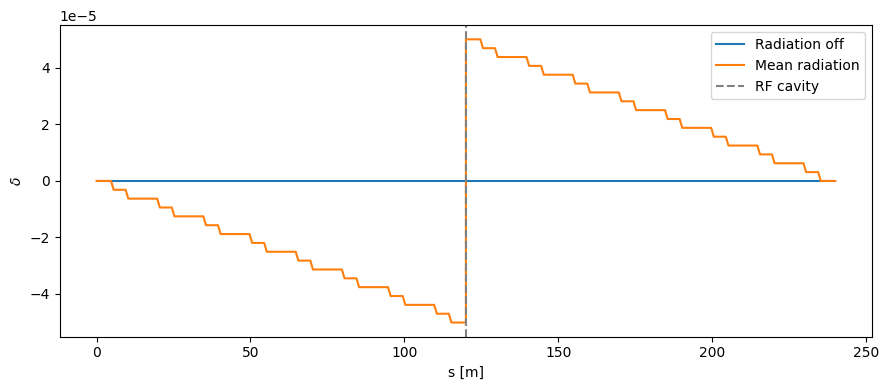

In [5]:
plt.figure(figsize=(9, 4))
plt.plot(tw_no_rad.s, tw_no_rad.delta, label='Radiation off')
plt.plot(tw_rad.s, tw_rad.delta, label='Mean radiation')
plt.axvline(s_rf, color='grey', linestyle='--', label='RF cavity')
plt.xlabel('s [m]')
plt.ylabel(r'$\delta$')
plt.legend()
plt.tight_layout()

### Track with mean radiation

Start from the radiating closed orbit and add 2 mm offsets in x and y and a momentum offset of 0.006. Track for four times the slowest amplitude damping time, recording the particle once per turn.

In [6]:
particle_on_co = tw_rad.particle_on_co
particle_initial = particle_on_co.copy()
particle_initial.x += 2e-3  # m
particle_initial.y += 2e-3  # m
particle_initial.delta += 6e-3

tau_turns = 1 / tw_rad.damping_constants_turns
num_turns = int(np.ceil(4 * np.max(tau_turns)))
print('Number of turns:', num_turns)

Number of turns: 80192


In [7]:
particle_mean = particle_initial.copy()
ring.track(particle_mean, num_turns=num_turns, turn_by_turn_monitor=True,
           time=True)
mon_mean = ring.record_last_track
print(f'Tracking time: {ring.time_last_track:.2f} s')
print('Particle survived:', particle_mean.state[0] > 0)

Tracking time: 20.92 s
Particle survived: True


### Observe damping

Plot x, y, and delta relative to the closed orbit at the observation point.

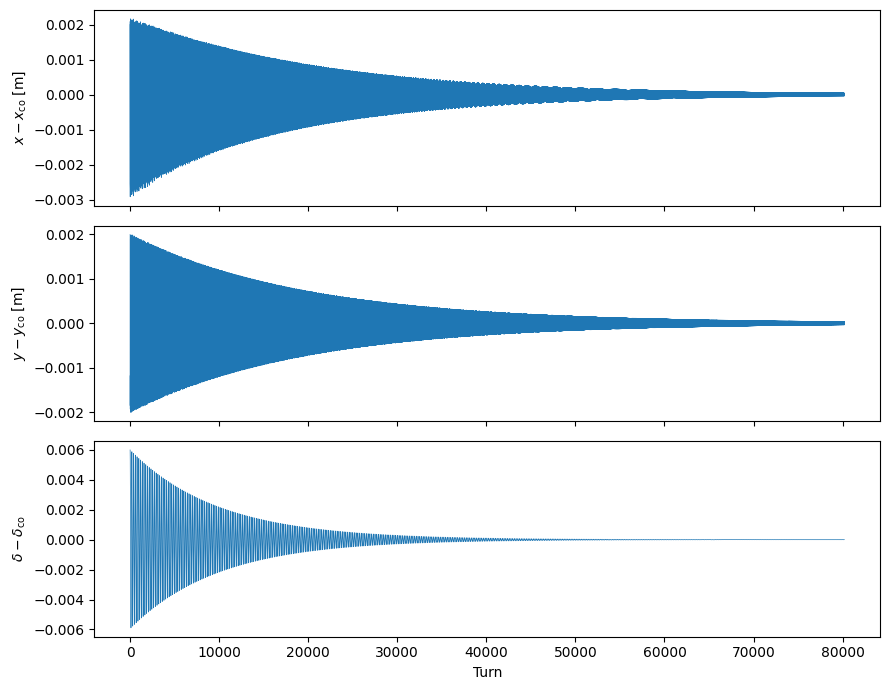

In [8]:
fig, axes = plt.subplots(3, 1, sharex=True, figsize=(9, 7))
axes[0].plot(mon_mean.at_turn[0], mon_mean.x[0] - particle_on_co.x[0], linewidth=0.5)
axes[0].set_ylabel(r'$x-x_{\mathrm{co}}$ [m]')
axes[1].plot(mon_mean.at_turn[0], mon_mean.y[0] - particle_on_co.y[0], linewidth=0.5)
axes[1].set_ylabel(r'$y-y_{\mathrm{co}}$ [m]')
axes[2].plot(mon_mean.at_turn[0], mon_mean.delta[0] - particle_on_co.delta[0], linewidth=0.5)
axes[2].set_ylabel(r'$\delta-\delta_{\mathrm{co}}$')
axes[2].set_xlabel('Turn')
plt.tight_layout()

### Switch to quantum radiation

Use `model='quantum'` to include random photon emission. Start from the same initial particle and track for the same number of turns. Reuse the closed orbit calculated in mean mode.

In [9]:
ring.configure_radiation(model='quantum')
particle_quantum = particle_initial.copy()
ring.track(particle_quantum, num_turns=num_turns, turn_by_turn_monitor=True,
           time=True)
mon_quantum = ring.record_last_track
print(f'Tracking time: {ring.time_last_track:.2f} s')
print('Particle survived:', particle_quantum.state[0] > 0)

Tracking time: 21.52 s
Particle survived: True


### Compare mean and quantum radiation

Which oscillations continue to fluctuate after damping? Why does the vertical motion behave differently in this ideal planar ring?

These are single-particle trajectories, not a measurement of the beam emittances.

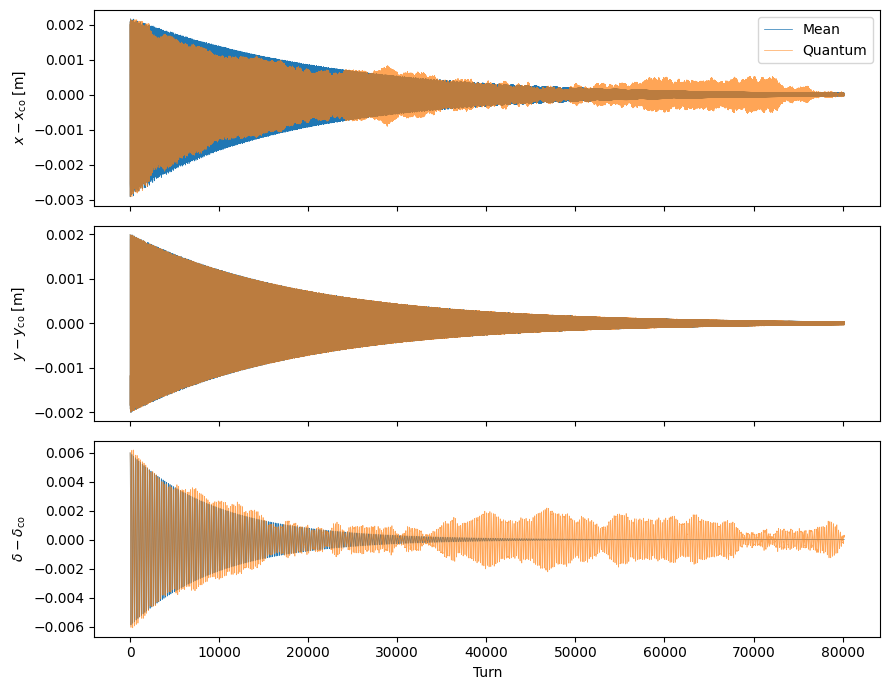

In [10]:
fig, axes = plt.subplots(3, 1, sharex=True, figsize=(9, 7))
axes[0].plot(mon_mean.at_turn[0], mon_mean.x[0] - particle_on_co.x[0],
             linewidth=0.5, label='Mean')
axes[0].plot(mon_quantum.at_turn[0], mon_quantum.x[0] - particle_on_co.x[0],
             linewidth=0.5, alpha=0.7, label='Quantum')
axes[0].set_ylabel(r'$x-x_{\mathrm{co}}$ [m]')
axes[0].legend()

axes[1].plot(mon_mean.at_turn[0], mon_mean.y[0] - particle_on_co.y[0], linewidth=0.5)
axes[1].plot(mon_quantum.at_turn[0], mon_quantum.y[0] - particle_on_co.y[0],
             linewidth=0.5, alpha=0.7)
axes[1].set_ylabel(r'$y-y_{\mathrm{co}}$ [m]')

axes[2].plot(mon_mean.at_turn[0], mon_mean.delta[0] - particle_on_co.delta[0], linewidth=0.5)
axes[2].plot(mon_quantum.at_turn[0], mon_quantum.delta[0] - particle_on_co.delta[0],
             linewidth=0.5, alpha=0.7)
axes[2].set_ylabel(r'$\delta-\delta_{\mathrm{co}}$')
axes[2].set_xlabel('Turn')
plt.tight_layout()